DTSC 5505 - Final Project

Project name: Predicting Depression Risk Among Students Using
Machine Learning

Student Names : Sindhujha Gopi, Yuvasri Kumar

Professor name: Preethom Roy



In [ ]:
import numpy as np
import pandas as pd
dataset = pd.read_csv('/content/Student Depression Dataset.csv')

In [ ]:
dataset.head()

,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


In [ ]:
print(dataset.isnull().sum())

id                                       0
Gender                                   0
Age                                      0
City                                     0
Profession                               0
Academic Pressure                        0
Work Pressure                            0
CGPA                                     0
Study Satisfaction                       0
Job Satisfaction                         0
Sleep Duration                           0
Dietary Habits                           0
Degree                                   0
Have you ever had suicidal thoughts ?    0
Work/Study Hours                         0
Financial Stress                         3
Family History of Mental Illness         0
Depression                               0
dtype: int64


In [ ]:
# Calculate the percentage of missing values for each column
missing_percentage = dataset.isnull().sum() / len(dataset) * 100
print("\nPercentage of missing values per column:\n", missing_percentage)


Percentage of missing values per column:
 id                                       0.000000
Gender                                   0.000000
Age                                      0.000000
City                                     0.000000
Profession                               0.000000
Academic Pressure                        0.000000
Work Pressure                            0.000000
CGPA                                     0.000000
Study Satisfaction                       0.000000
Job Satisfaction                         0.000000
Sleep Duration                           0.000000
Dietary Habits                           0.000000
Degree                                   0.000000
Have you ever had suicidal thoughts ?    0.000000
Work/Study Hours                         0.000000
Financial Stress                         0.010752
Family History of Mental Illness         0.000000
Depression                               0.000000
dtype: float64


From the above output, we can see that 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Sleep Duration', 'Work/Study Hours', and 'Financial Stress' columns have missing values. 'City', 'Profession', 'Dietary Habits', 'Degree', 'Have you ever had suicidal thoughts ?', and 'Family History of Mental Illness' also have missing values.

Since the number of missing values is relatively small for numerical columns, I'll impute them with the mean. For categorical columns, I'll impute with the mode.

In [ ]:
# Impute numerical columns with the mean
for col in ['Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Work/Study Hours', 'Financial Stress']:
    if dataset[col].isnull().any():
        dataset[col] = dataset[col].fillna(dataset[col].mean())

# Impute 'Sleep Duration' with the mode as it's categorical-like
if dataset['Sleep Duration'].isnull().any():
    dataset['Sleep Duration'] = dataset['Sleep Duration'].fillna(dataset['Sleep Duration'].mode()[0])

# Impute categorical columns with the mode
for col in ['City', 'Profession', 'Dietary Habits', 'Degree', 'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']:
    if dataset[col].isnull().any():
        dataset[col] = dataset[col].fillna(dataset[col].mode()[0])

print("Missing values after imputation:")
print(dataset.isnull().sum())

Missing values after imputation:
id                                       0
Gender                                   0
Age                                      0
City                                     0
Profession                               0
Academic Pressure                        0
Work Pressure                            0
CGPA                                     0
Study Satisfaction                       0
Job Satisfaction                         0
Sleep Duration                           0
Dietary Habits                           0
Degree                                   0
Have you ever had suicidal thoughts ?    0
Work/Study Hours                         0
Financial Stress                         0
Family History of Mental Illness         0
Depression                               0
dtype: int64


In [ ]:
print("\n--- Descriptive Statistics for Numerical Columns ---\n")
print(dataset.describe())

print("\n--- Value Counts for Categorical Columns ---\n")
for column in dataset.select_dtypes(include='object').columns:
    print(f"\nValue counts for column '{column}':")
    print(dataset[column].value_counts())
    print("--------------------------------------------------")



--- Descriptive Statistics for Numerical Columns ---

                  id           Age  Academic Pressure  Work Pressure  \
count   27901.000000  27901.000000       27901.000000   27901.000000   
mean    70442.149421     25.822300           3.141214       0.000430   
std     40641.175216      4.905687           1.381465       0.043992   
min         2.000000     18.000000           0.000000       0.000000   
25%     35039.000000     21.000000           2.000000       0.000000   
50%     70684.000000     25.000000           3.000000       0.000000   
75%    105818.000000     30.000000           4.000000       0.000000   
max    140699.000000     59.000000           5.000000       5.000000   

               CGPA  Study Satisfaction  Job Satisfaction  Work/Study Hours  \
count  27901.000000        27901.000000      27901.000000      27901.000000   
mean       7.656104            2.943837          0.000681          7.156984   
std        1.470707            1.361148          0.044394  

### Visualizing Numerical Features

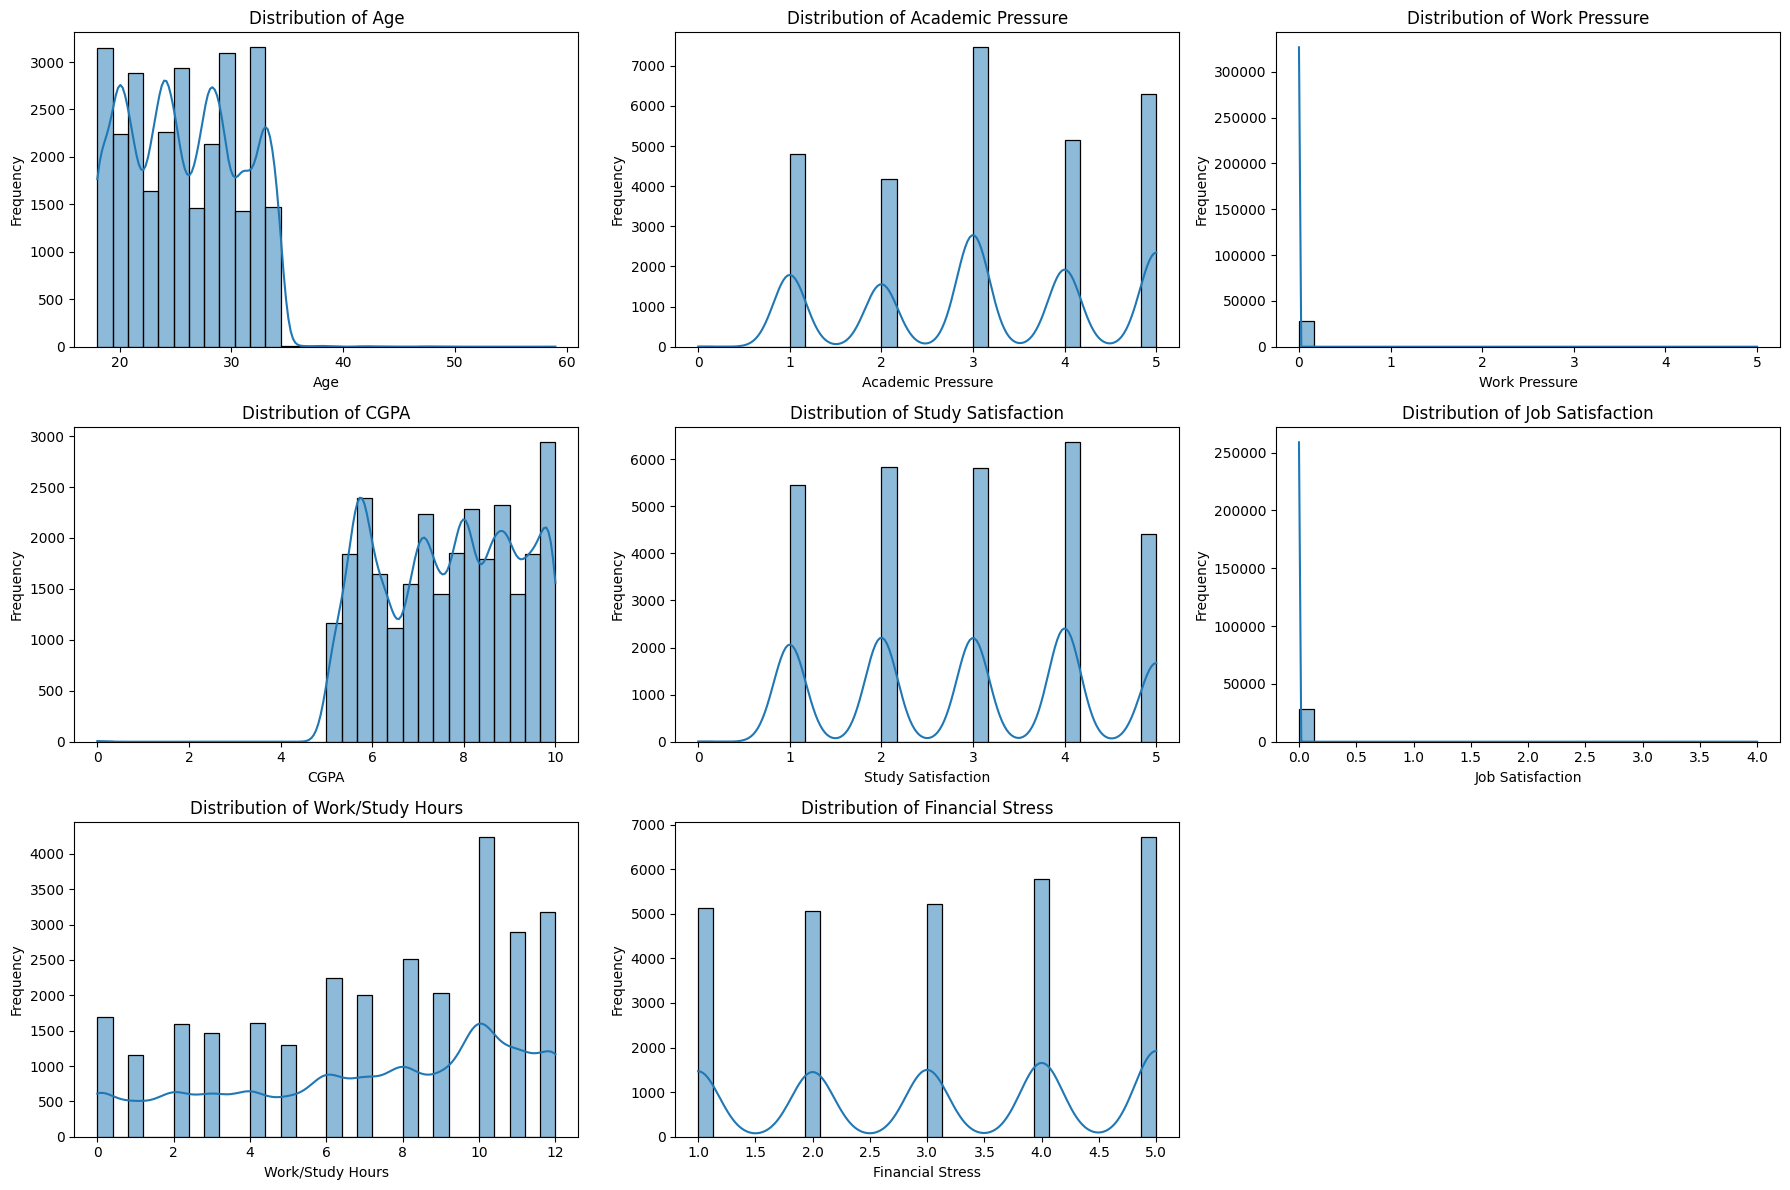

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = ['Age', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Work/Study Hours', 'Financial Stress']

plt.figure(figsize=(18, 12))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i + 1) # Adjust subplot grid as needed
    sns.histplot(dataset[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

### Visualizing Categorical Features

/tmp/ipykernel_5343/870849710.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=dataset, x=col, palette='viridis')
/tmp/ipykernel_5343/870849710.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=dataset, x=col, palette='viridis')
/tmp/ipykernel_5343/870849710.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=dataset, x=col, palette='viridis')
/tmp/ipykernel_5343/870849710.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` a

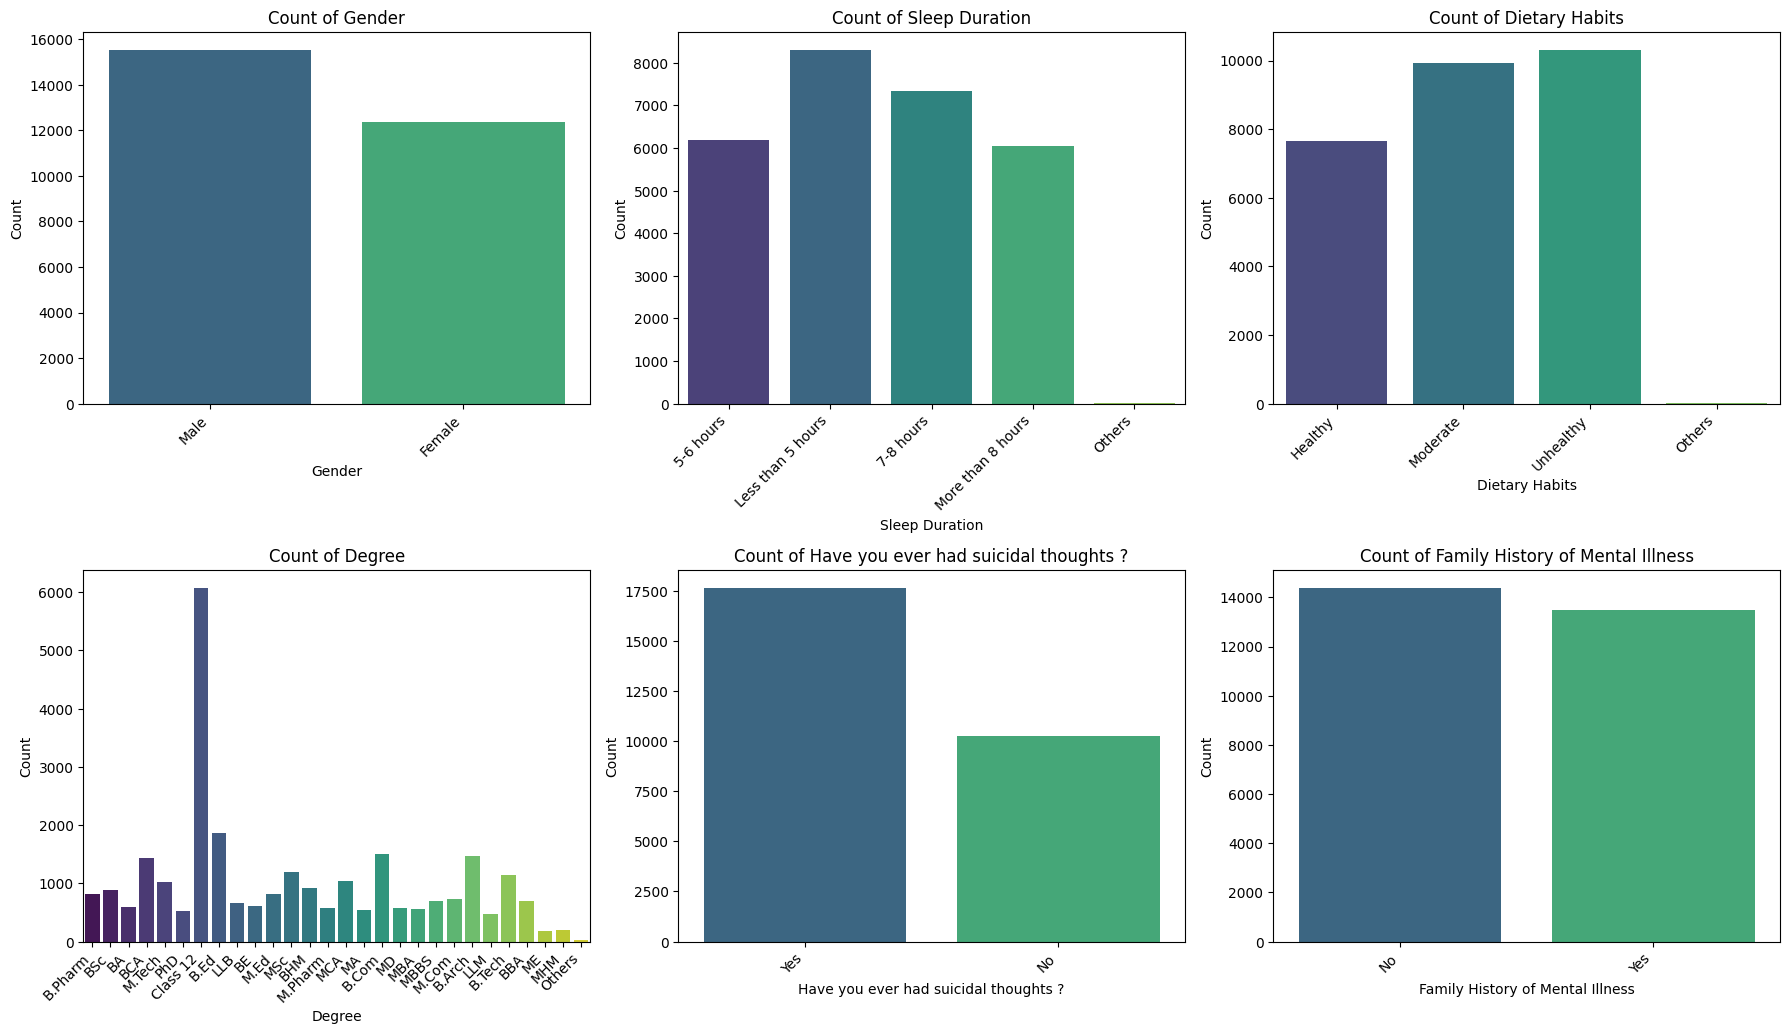

In [ ]:
categorical_cols = ['Gender', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']

plt.figure(figsize=(18, 15))
for i, col in enumerate(categorical_cols):
    plt.subplot(3, 3, i + 1) # Adjust subplot grid as needed
    sns.countplot(data=dataset, x=col, palette='viridis')
    plt.title(f'Count of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Relationship with Depression (Target Variable)

/tmp/ipykernel_5343/61932756.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dataset, x='Depression', y=col, palette='pastel')
/tmp/ipykernel_5343/61932756.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dataset, x='Depression', y=col, palette='pastel')
/tmp/ipykernel_5343/61932756.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dataset, x='Depression', y=col, palette='pastel')
/tmp/ipykernel_5343/61932756.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0.

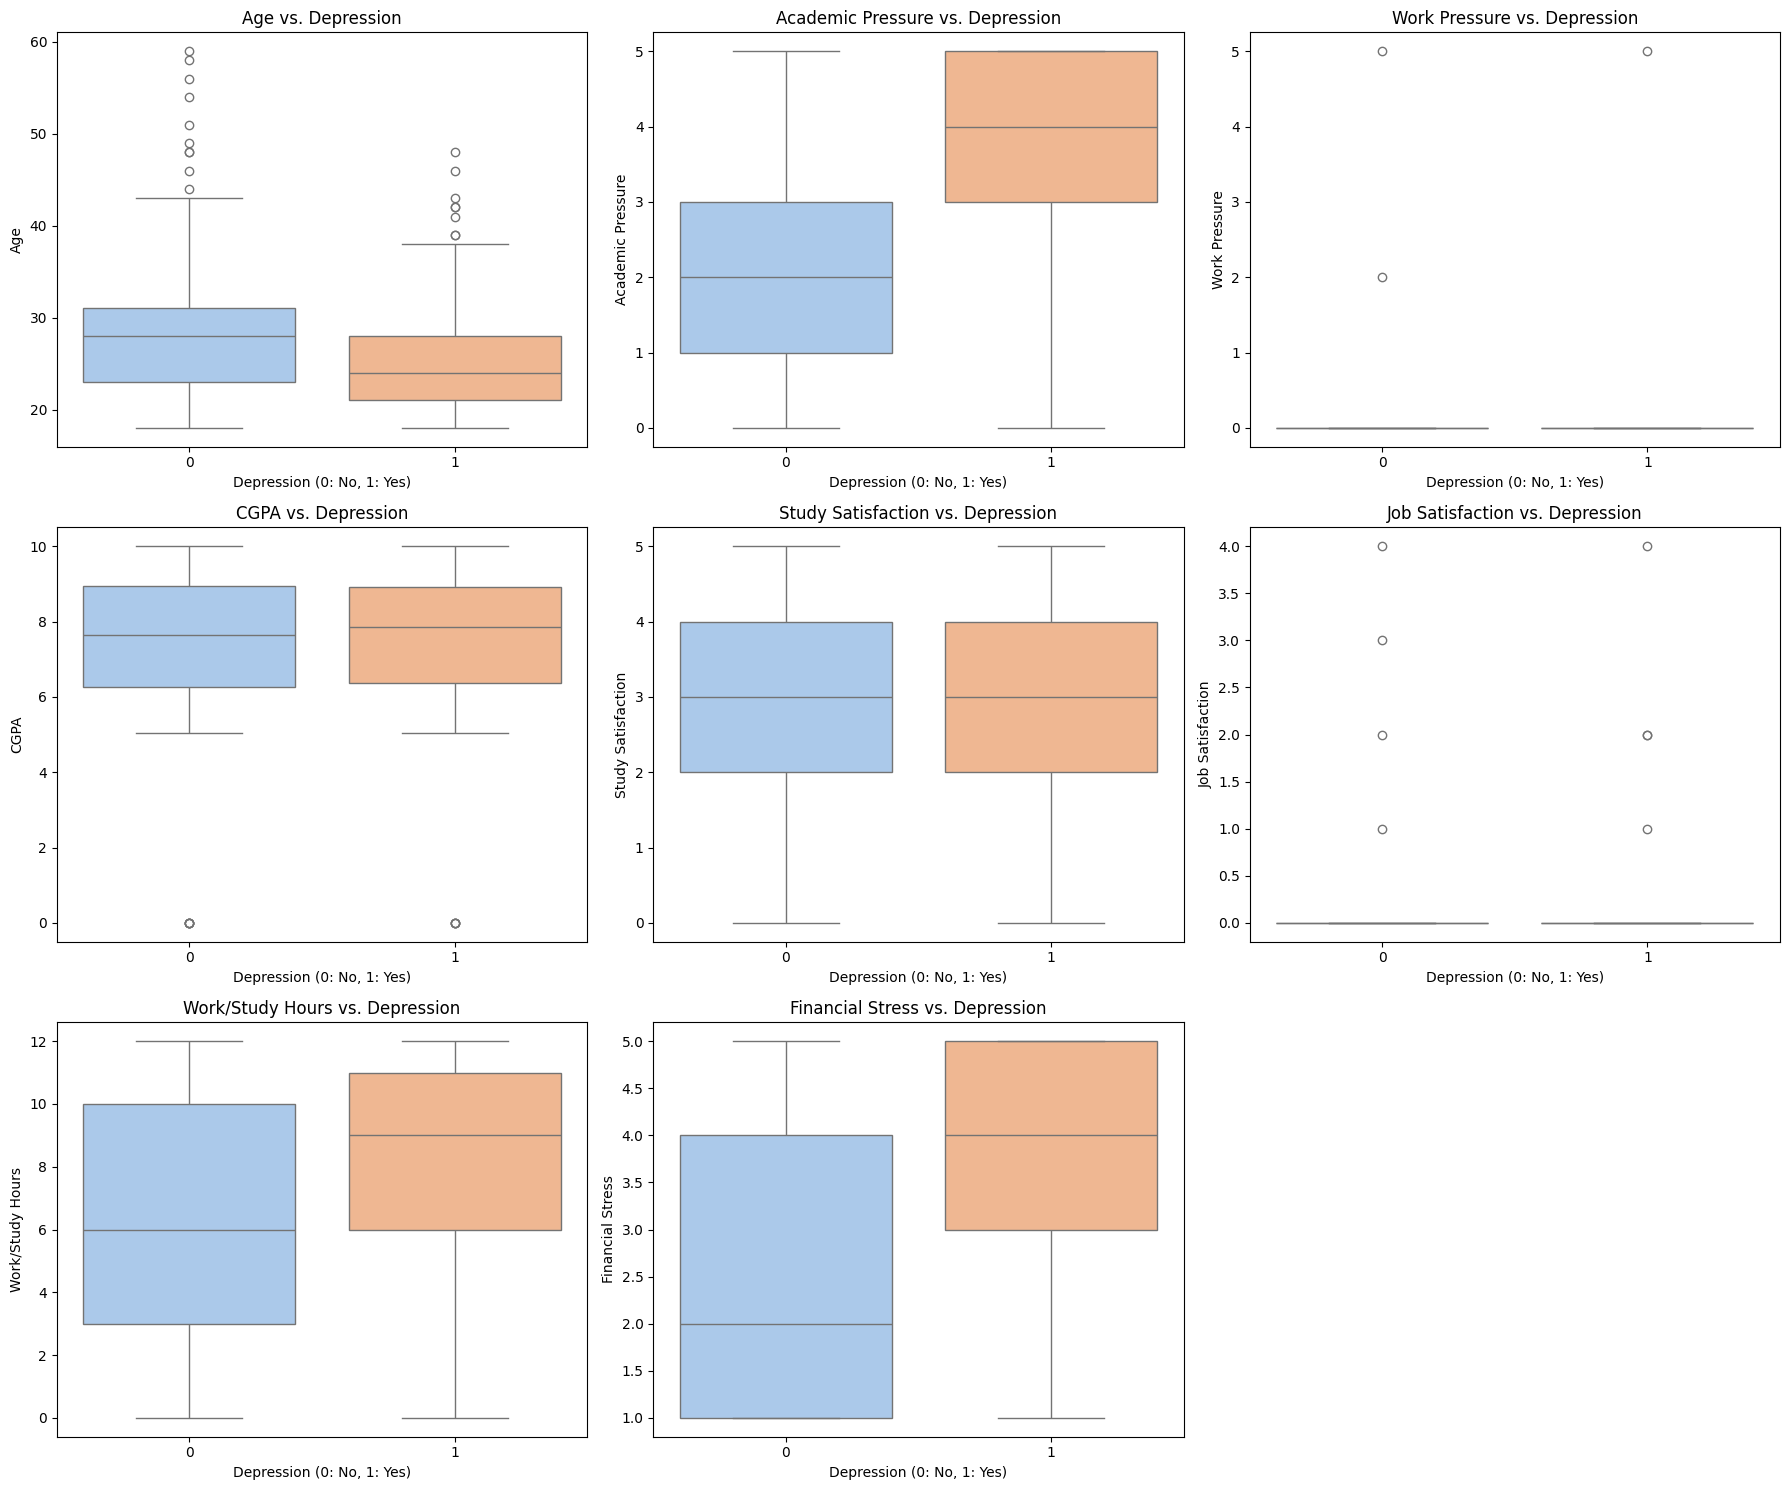

In [ ]:
plt.figure(figsize=(18, 15))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(data=dataset, x='Depression', y=col, palette='pastel')
    plt.title(f'{col} vs. Depression')
    plt.xlabel('Depression (0: No, 1: Yes)')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

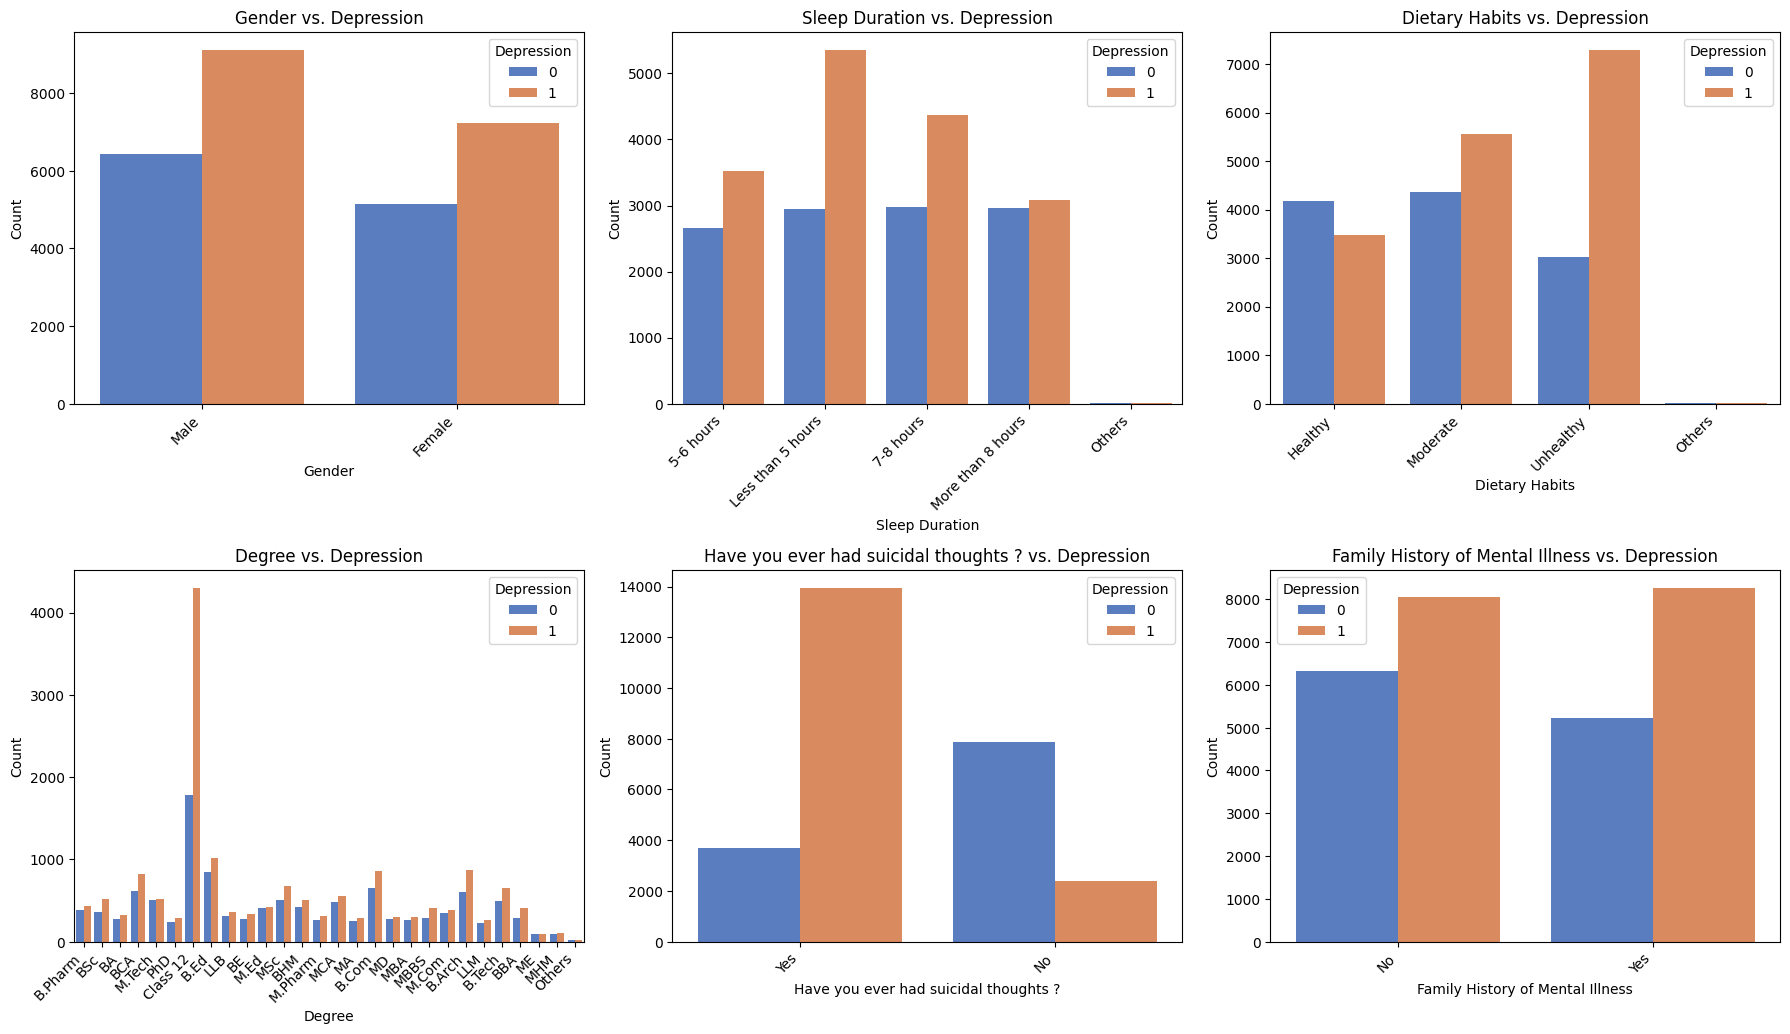

In [ ]:
plt.figure(figsize=(18, 15))
for i, col in enumerate(categorical_cols):
    plt.subplot(3, 3, i + 1)
    sns.countplot(data=dataset, x=col, hue='Depression', palette='muted')
    plt.title(f'{col} vs. Depression')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Depression')
plt.tight_layout()
plt.show()

XGBOOSt


### Feature Selection and Data Preparation

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import xgboost as xgb

# Define features (X) and target (y)
X = dataset[['Financial Stress', 'Academic Pressure', 'Work/Study Hours']]
y = dataset['Depression']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)
print("Training features (X_train) shape:", X_train.shape)
print("Testing features (X_test) shape:", X_test.shape)


Features (X) shape: (27901, 3)
Target (y) shape: (27901,)
Training features (X_train) shape: (19530, 3)
Testing features (X_test) shape: (8371, 3)


### XGBoost Model Training and Evaluation

In [ ]:
# Initialize the XGBoost Classifier
model = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', use_label_encoder=False, random_state=42)

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print("Classification Report:\n", report)


Accuracy: 0.7635
Classification Report:
               precision    recall  f1-score   support

           0       0.74      0.67      0.70      3505
           1       0.78      0.83      0.80      4866

    accuracy                           0.76      8371
   macro avg       0.76      0.75      0.75      8371
weighted avg       0.76      0.76      0.76      8371



/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [03:06:31] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


### TabNet Model Training and Evaluation

In [ ]:
# Install pytorch-tabnet if not already installed
!pip install pytorch-tabnet

# Import TabNetClassifier
from pytorch_tabnet.tab_model import TabNetClassifier
import torch

# Prepare data for TabNet (it prefers numpy arrays)
X_train_np = X_train.values
X_test_np = X_test.values
y_train_np = y_train.values
y_test_np = y_test.values

# Initialize TabNetClassifier
tabnet_model = TabNetClassifier(verbose=0, seed=42)

# Train the model
tabnet_model.fit(X_train_np, y_train_np, eval_set=[(X_test_np, y_test_np)], patience=10, max_epochs=100)

# Make predictions on the test set
y_pred_tabnet = tabnet_model.predict(X_test_np)

# Evaluate the model
accuracy_tabnet = accuracy_score(y_test_np, y_pred_tabnet)
report_tabnet = classification_report(y_test_np, y_pred_tabnet)

print(f"TabNet Accuracy: {accuracy_tabnet:.4f}")
print("TabNet Classification Report:\n", report_tabnet)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 716.7 kB/s eta 0:00:00

Early stopping occurred at epoch 29 with best_epoch = 19 and best_val_0_auc = 0.83755


/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


TabNet Accuracy: 0.7666
TabNet Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.63      0.69      3505
           1       0.77      0.86      0.81      4866

    accuracy                           0.77      8371
   macro avg       0.77      0.75      0.75      8371
weighted avg       0.77      0.77      0.76      8371



### Random Forest Model Training and Evaluation

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest Classifier
rf_model = RandomForestClassifier(random_state=42)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
accuracy_rf = accuracy_score(y_test, y_pred_rf)
report_rf = classification_report(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {accuracy_rf:.4f}")
print("Random Forest Classification Report:\n", report_rf)

Random Forest Accuracy: 0.7643
Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.73      0.68      0.71      3505
           1       0.78      0.82      0.80      4866

    accuracy                           0.76      8371
   macro avg       0.76      0.75      0.76      8371
weighted avg       0.76      0.76      0.76      8371



### Logistic Regression Model Training and Evaluation

In [ ]:
from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression Classifier
log_reg_model = LogisticRegression(random_state=42, solver='liblinear') # 'liblinear' is good for small datasets and handles L1/L2 penalties

# Train the model
log_reg_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_log_reg = log_reg_model.predict(X_test)

# Evaluate the model
accuracy_log_reg = accuracy_score(y_test, y_pred_log_reg)
report_log_reg = classification_report(y_test, y_pred_log_reg)

print(f"Logistic Regression Accuracy: {accuracy_log_reg:.4f}")
print("Logistic Regression Classification Report:\n", report_log_reg)

Logistic Regression Accuracy: 0.7686
Logistic Regression Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.67      0.71      3505
           1       0.78      0.84      0.81      4866

    accuracy                           0.77      8371
   macro avg       0.76      0.75      0.76      8371
weighted avg       0.77      0.77      0.77      8371

